In [1]:
import pandas as pd

customer_features = pd.read_csv(
    "../data/processed/customer_features.csv",
    index_col=0
)

customer_features.index.name = "Customer ID"

print("Dataset shape:", customer_features.shape)
display(customer_features.head())

Dataset shape: (3361, 5)


,recency_days,invoice_count,total_quantity,total_spend,repurchased
Customer ID,,,,,
12346.0,72,11,70,372.86,0
12349.0,113,2,474,1268.52,1
12355.0,110,1,303,488.21,0
12358.0,93,2,590,1697.93,1
12359.0,78,5,877,2012.03,1


In [3]:
import numpy as np
# Define features and target
feature_columns = [
    "recency_days",
    "invoice_count",
    "total_quantity",
    "total_spend"
]

X = customer_features[feature_columns].copy()
y = customer_features["repurchased"].astype(int)

# Reduce skewness in purchase volume and spending
X["total_quantity"] = np.log1p(X["total_quantity"])
X["total_spend"] = np.log1p(X["total_spend"])

print("Features shape:", X.shape)
print("\nTarget distribution:")
display(
    y.value_counts()
    .rename(index={0: "No repurchase", 1: "Repurchase"})
    .to_frame("customer_count")
)


Features shape: (3361, 4)

Target distribution:


,customer_count
repurchased,
Repurchase,1951
No repurchase,1410


In [4]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)

# Initial baseline split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

print("Classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print(f"PR-AUC: {average_precision_score(y_test, y_proba):.3f}")


Classification report:
              precision    recall  f1-score   support

           0       0.61      0.58      0.59       282
           1       0.71      0.73      0.72       391

    accuracy                           0.67       673
   macro avg       0.66      0.65      0.65       673
weighted avg       0.66      0.67      0.66       673

Confusion matrix:
[[163 119]
 [106 285]]
ROC-AUC: 0.721
PR-AUC: 0.784


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

random_forest = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)
rf_proba = random_forest.predict_proba(X_test)[:, 1]

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_proba),
    "PR-AUC": average_precision_score(y_test, rf_proba)
}

display(pd.DataFrame([rf_results]).round(3))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.64,0.722,0.619,0.667,0.704,0.787


### Comparação dos Modelos e Limitações

A Regressão Logística apresentou os melhores resultados gerais na avaliação inicial, com F1-score de 0,72 e ROC-AUC de 0,721. O Random Forest obteve valores ligeiramente superiores de Precision e PR-AUC, mas apresentou menor Recall e F1-score.

Esses resultados são preliminares, pois a avaliação utilizou uma divisão aleatória entre treino e teste. É necessária uma validação temporal adicional para avaliar a capacidade dos modelos de generalizar para períodos futuros de compra. As probabilidades previstas representam a propensão à recompra, e não o impacto causal de campanhas de marketing.

### Model Comparison and Limitations

Logistic Regression achieved the best overall results in the initial evaluation, with an F1-score of 0.72 and a ROC-AUC of 0.721. Random Forest achieved slightly higher Precision and PR-AUC, but lower Recall and F1-score.

These results are preliminary because the evaluation used a random train-test split. Further temporal validation is needed to assess how well the models generalize to future purchasing periods. The predicted probabilities indicate purchase propensity, not causal campaign impact.

,Feature,Logistic Regression,Random Forest
1,invoice_count,0.928619,0.177855
0,recency_days,-0.242062,0.240998
2,total_quantity,0.237158,0.262744
3,total_spend,0.202685,0.318403


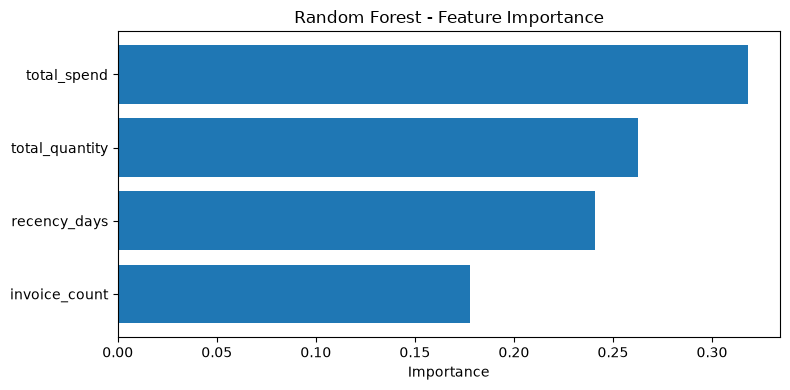

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Logistic Regression coefficients
logistic_model = baseline_model.named_steps["model"]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Logistic Regression": logistic_model.coef_[0],
    "Random Forest": random_forest.feature_importances_
})

feature_importance["Logistic Abs. Importance"] = (
    feature_importance["Logistic Regression"].abs()
)

display(
    feature_importance.sort_values(
        "Logistic Abs. Importance",
        ascending=False
    ).drop(columns="Logistic Abs. Importance")
)

# Plot Random Forest feature importance
rf_importance = feature_importance.sort_values(
    "Random Forest",
    ascending=True
)

plt.figure(figsize=(8, 4))
plt.barh(rf_importance["Feature"], rf_importance["Random Forest"])
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
